In [1]:
import sys
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

sys.path.insert(0, str(Path("../src").resolve()))
%load_ext autoreload
%autoreload 2

DATA = Path("../data/processed/criteo_uplift_v2.1.parquet")
SPLIT = Path("../data/processed/split.parquet")
FEATURES = [f"f{i}" for i in range(12)]

df = pd.read_parquet(DATA)

# Schichtung nach treatment × visit (4 Zellen), damit alle Splits gleiche Raten haben
strata = (df["treatment"].to_numpy() * 2 + df["visit"].to_numpy()).astype(np.int8)
idx = np.arange(len(df))
idx_train, idx_tmp = train_test_split(idx, test_size=0.4, stratify=strata, random_state=42)
idx_val, idx_test = train_test_split(idx_tmp, test_size=0.5, stratify=strata[idx_tmp], random_state=42)

split = np.empty(len(df), dtype=np.int8)   # 0 = train, 1 = val, 2 = test
split[idx_train], split[idx_val], split[idx_test] = 0, 1, 2
pd.DataFrame({"split": split}).to_parquet(SPLIT)
df["split"] = split

In [2]:
df.groupby(["split", "treatment"]).agg(n=("visit", "size"), visit_rate=("visit", "mean")).unstack()

n          visit_rate          
treatment        0        1          0         1
split                                           
0          1258162  7129593   0.038201  0.048543
1           419387  2376531   0.038201  0.048543
2           419388  2376531   0.038201  0.048543

oracle    qini_auc=+0.199  auuc=+0.199  uplift@20%=0.0198
random    qini_auc=-0.002  auuc=-0.003  uplift@20%=0.0099
reversed  qini_auc=-0.199  auuc=-0.199  uplift@20%=-0.0001


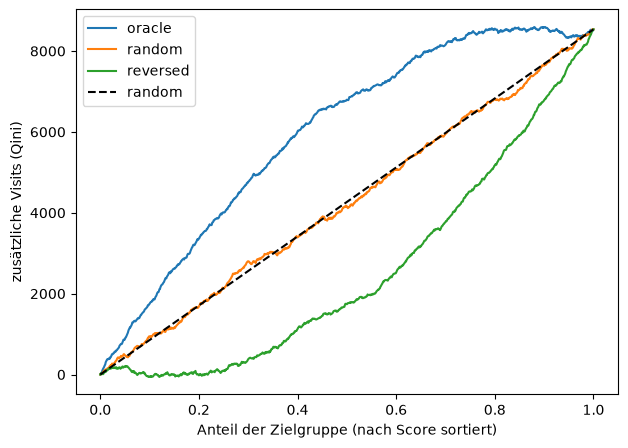

In [3]:
from uplift.metrics import qini_curve, qini_auc, auuc, uplift_at_k, plot_qini

rng = np.random.default_rng(0)
n = 1_000_000
x = rng.uniform(size=n)
w_sim = rng.binomial(1, 0.85, n)          # gleiches 85/15-Verhältnis wie Criteo
tau = 0.02 * x                            # wahrer Uplift steigt mit x
y_sim = rng.binomial(1, 0.04 + tau * w_sim)

scores = {"oracle": x, "random": rng.uniform(size=n), "reversed": -x}
for name, s in scores.items():
    print(f"{name:9s} qini_auc={qini_auc(y_sim, w_sim, s):+.3f}  "
          f"auuc={auuc(y_sim, w_sim, s):+.3f}  "
          f"uplift@20%={uplift_at_k(y_sim, w_sim, s, 0.2):.4f}")
plot_qini({k: qini_curve(y_sim, w_sim, s) for k, s in scores.items()});

In [4]:
test = df[df.split == 2]
print("ATE im Testset:", uplift_at_k(test.visit, test.treatment, np.zeros(len(test)), k=1.0))

ATE im Testset: 0.010342541937906811
